# 11 · Clean outer-fold uncertainty and referral diagnostics

Score variation under dropout masks and conservative image views can prioritise review differently from a high melanoma score. Repeat the original diagnostic depth on clean five-fold held-out records, with no historical checkpoints or inferred missing results.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [13_image_uncertainty.ipynb](../Subset/13_image_uncertainty.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '11_image_uncertainty'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## Explicit clean checkpoint scope and completion

Each retained image uses its own outer-held-out B0 checkpoint, fitted without that patient. Strict receipts bind the exact clean manifest, final selected duration, checkpoint bytes, source hashes and saved deterministic predictions. Full uncertainty waits for all five raw refits. A smoke check verifies repeatability, seeded dropout, identity TTA and unchanged model/BatchNorm state before costly inference.

In [2]:
from melanoma_detection import dedup_notebook_images as image_docs
uncertainty = image_docs.load_uncertainty(ROOT, dataset_identity)

,status,images,patients,malignant_images,malignant_patients,mc_passes,tta_passes,training_fits
0,complete,6706,422,127,88,30,4,0


## Inspect conservative whole-image views

Columns are identity, horizontal flip, vertical flip and both flips after deterministic preparation. Flips rearrange existing pixels; they add no crop, reflected border or interpolation. The examples are retained fitting photographs and illustrate framing, not a performance sample. This cell previews images only and starts no inference.

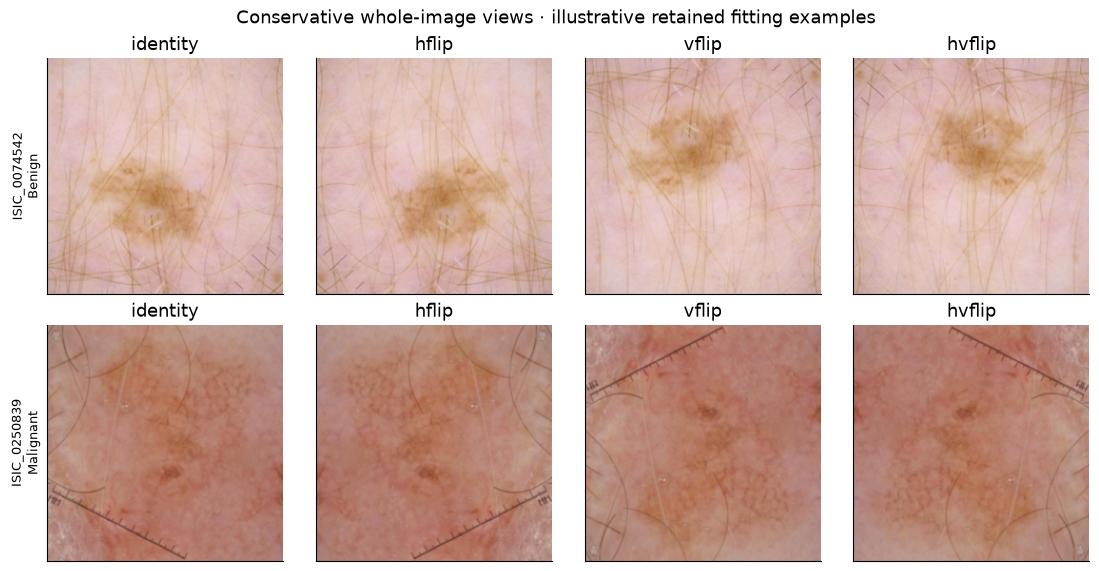

In [3]:
image_docs.uncertainty_views(ROOT, data, dataset_identity, finish_figure)

## Keep MC dropout and TTA separate

MC dropout makes 30 passes at the trained explicit-dropout rate. BatchNorm and stochastic depth remain in evaluation mode. Seed 20261004 and recorded pass seeds make masks repeatable. TTA uses four deterministic views with dropout disabled. Both use batch 64 and full precision. Means and sample SDs are computed separately; real held-out targets are joined only after prediction.

In [4]:
display(pd.DataFrame([{"Mode": "MC dropout", "Passes": 30, "Stochastic component": "explicit trained dropout only", "Seed": 20261004}, {"Mode": "TTA", "Passes": 4, "Stochastic component": "none; fixed tensor flips", "Seed": 20261004}]))

,Mode,Passes,Stochastic component,Seed
0,MC dropout,30,explicit trained dropout only,20261004
1,TTA,4,none; fixed tensor flips,20261004


## Validate pass coverage before aggregation

Every image/pass combination must occur exactly once with finite scores in [0,1] and matching patient/fold identities. Retained records total 6,706 images and 422 patients, including 127 malignant images from 88 patients. Saved raw passes allow independent means/SD recalculation. Deterministic scores must reproduce the checkpoint export within 1e-6, and the frozen saved values drive referral.

In [5]:
image_docs.uncertainty_checks(uncertainty)

,image_id,patient_id,fold,target,base_score,mc_mean_score,mc_score_sd,tta_mean_score,tta_score_sd
0,ISIC_0015719,IP_3075186,0,0,0.000130,0.000156,0.000076,0.000112,0.000040
1,ISIC_0074542,IP_4698288,1,0,0.000133,0.000143,0.000053,0.000137,0.000019
2,ISIC_0076545,IP_9802602,2,0,0.017711,0.017909,0.003248,0.020957,0.002302
3,ISIC_0082348,IP_7684360,0,0,0.000249,0.000266,0.000095,0.000282,0.000067
4,ISIC_0085172,IP_1705144,1,0,0.000010,0.000010,0.000006,0.000015,0.000004
5,ISIC_0086349,IP_2825529,2,0,0.008073,0.008435,0.002625,0.007279,0.001150
6,ISIC_0086632,IP_2114130,4,0,0.000098,0.000124,0.000103,0.000095,0.000005
7,ISIC_0087297,IP_5389392,4,0,0.000059,0.000070,0.000041,0.000060,0.000006


,all_protected_files_unchanged,batchnorm_buffers_checked,batchnorm_buffers_unchanged,checkpoint_compatibility,evaluation_image_hashes_verified,fold,identity_tta_agreement,model_state_unchanged,only_explicit_dropout_active,patient_separation,protected_files_checked,saved_prediction_max_abs_difference,saved_predictions_agree,trained_dropout_rate_preserved
0,True,147,True,True,1344,0,True,True,True,True,8,1.110223e-16,True,True
1,True,147,True,True,1366,1,True,True,True,True,8,9.985502e-17,True,True
2,True,147,True,True,1328,2,True,True,True,True,8,9.974660e-17,True,True
3,True,147,True,True,1371,3,True,True,True,True,8,9.955686e-17,True,True
4,True,147,True,True,1297,4,True,True,True,True,8,1.110223e-16,True,True


,images,patients,malignant_images,expected_MC_rows,expected_TTA_rows
fold,,,,,
0,1344,84,24,40320,5376
1,1366,84,26,40980,5464
2,1328,87,26,39840,5312
3,1371,82,25,41130,5484
4,1297,85,26,38910,5188


,Total MC rows,Total TTA rows,Cutoff fitting,Calibration fitting,BN updates,Referral score
0,201180,26824,False,False,False,Frozen deterministic saved score


## Numerical and ranking stability with more passes

Compare prefixes of 5, 10 and 20 passes against the same 30-pass reference. Smaller score/SD mean absolute differences suggest numerical stability; Spearman correlation closer to one suggests a stable SD ordering. Draws and pass count are prescribed rather than selected from labels. Lines are preserved outer folds; stability is not predictive correctness.

,n_passes,reference_passes,mean_score_mae,score_sd_mae,sd_spearman,top20_overlap_fraction,fold
0,5,30,0.001191,0.001018,0.979092,0.914498,0
1,10,30,0.000751,0.000606,0.991070,0.951673,0
2,20,30,0.000385,0.000279,0.997707,0.977695,0
3,5,30,0.000740,0.000749,0.982927,0.894161,1
4,10,30,0.000442,0.000420,0.992714,0.930657,1
5,20,30,0.000228,0.000215,0.998229,0.970803,1
6,5,30,0.000671,0.000592,0.969093,0.906015,2
7,10,30,0.000448,0.000349,0.986593,0.928571,2
8,20,30,0.000218,0.000180,0.995896,0.969925,2
9,5,30,0.000239,0.000257,0.981947,0.894545,3


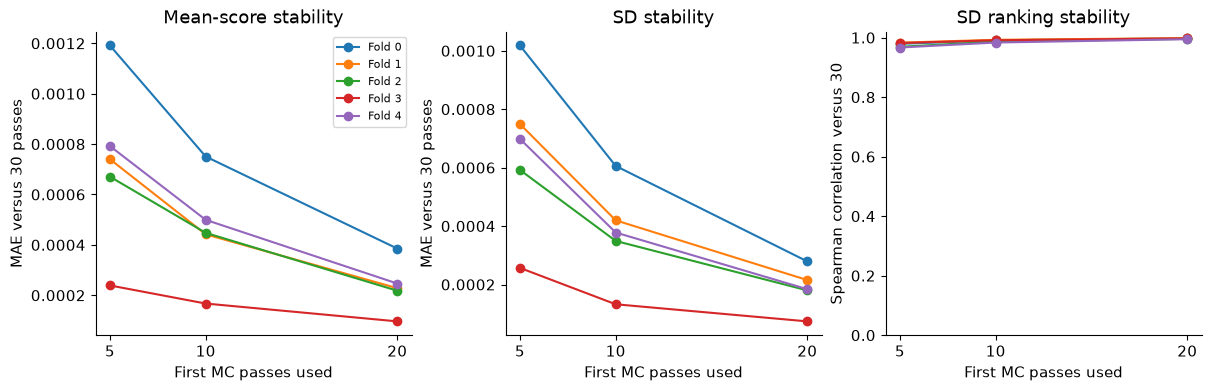

In [6]:
image_docs.uncertainty_convergence(uncertainty, finish_figure)

## Ranking and descriptive reliability of averaged scores

Report deterministic, MC-mean and TTA-mean AP/AUC, log loss and Brier on each outer fold, with unweighted mean-fold summaries primary. Constant fitting prevalence is computed separately from each fold’s training patients. Pooled ROC/PR and equal-count reliability are descriptive. A favourable mean score does not prove SD improves referral and does not replace the training-only calibration/cutoff procedure.

,fold,mode,images,patients,malignant_images,average_precision,roc_auc,log_loss,brier
0,0,deterministic,1344,84,24,0.152537,0.854419,0.095513,0.022482
1,0,mc,1344,84,24,0.154791,0.856660,0.094917,0.022484
2,0,tta,1344,84,24,0.139996,0.851010,0.093828,0.022084
3,1,deterministic,1366,84,26,0.148876,0.839179,0.090245,0.019154
4,1,mc,1366,84,26,0.154862,0.837887,0.090163,0.019183
5,1,tta,1366,84,26,0.139101,0.847130,0.088172,0.019063
6,2,deterministic,1328,87,26,0.148730,0.864823,0.082345,0.018674
7,2,mc,1328,87,26,0.149296,0.866507,0.081756,0.018637
8,2,tta,1328,87,26,0.135721,0.858768,0.083377,0.018691
9,3,deterministic,1371,82,25,0.057262,0.757266,0.138206,0.018364


,mode,average_precision,roc_auc,log_loss,brier
0,deterministic,0.131570,0.830801,0.099116,0.019637
1,mc,0.133261,0.830044,0.098709,0.019634
2,tta,0.125830,0.830146,0.097910,0.019443
3,constant fitting prevalence,0.018950,0.500000,0.093934,0.018591


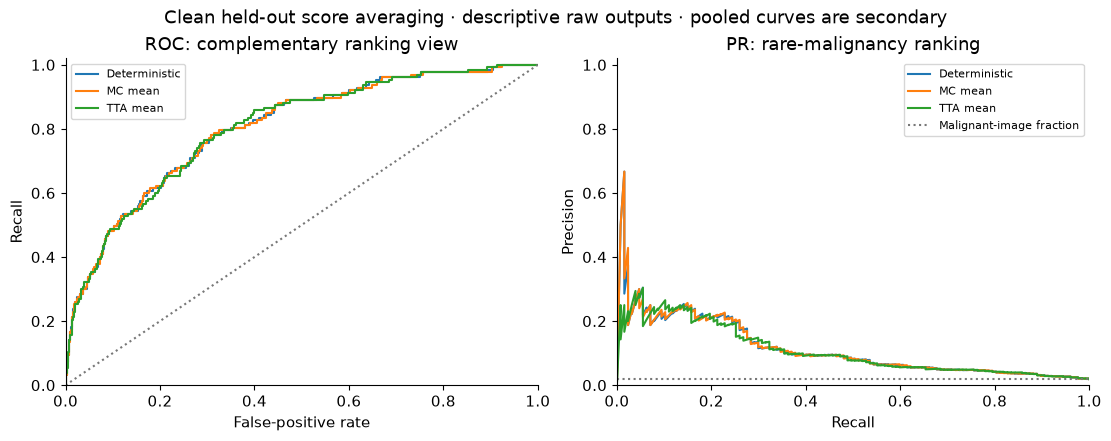

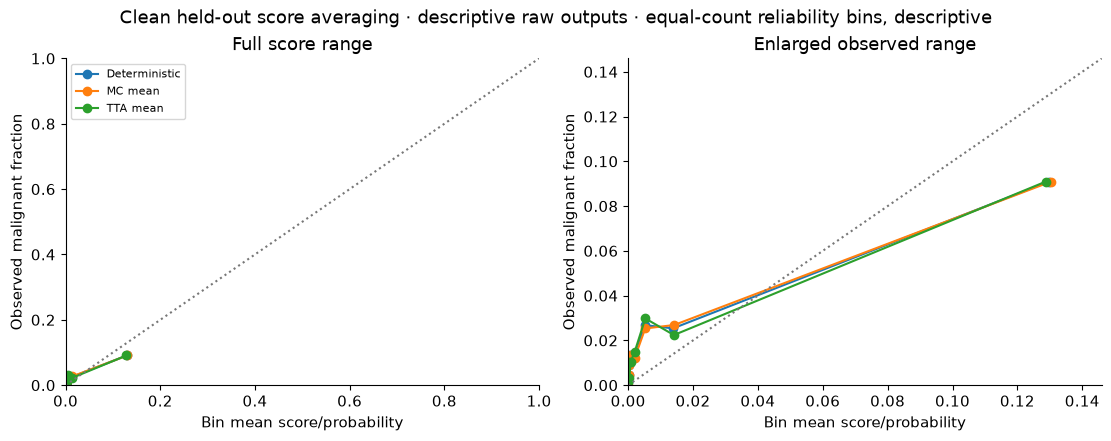

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,671,2,0.000004,0.002981,2.590740e-09,0.000013,79,Deterministic
1,2,671,1,0.000031,0.001490,1.319787e-05,0.000050,154,Deterministic
2,3,670,2,0.000074,0.002985,4.980170e-05,0.000103,178,Deterministic
3,4,671,6,0.000145,0.008942,1.030144e-04,0.000201,192,Deterministic
4,5,670,3,0.000313,0.004478,2.014816e-04,0.000447,220,Deterministic
5,6,671,9,0.000721,0.013413,4.477781e-04,0.001118,241,Deterministic
6,7,670,8,0.001890,0.011940,1.118944e-03,0.003053,252,Deterministic
7,8,671,18,0.005082,0.026826,3.058046e-03,0.007783,259,Deterministic
8,9,670,17,0.013827,0.025373,7.784358e-03,0.022908,244,Deterministic
9,10,671,61,0.129615,0.090909,2.294426e-02,0.991087,223,Deterministic


In [7]:
image_docs.uncertainty_quality(uncertainty, data, finish_figure)

## What SD and predictive entropy capture

Histograms show dropout-mask and orientation sensitivity on their own scales. The scatter compares MC and TTA SD on the same images. Predictive entropy −s log(s) − (1−s) log(1−s) prioritises scores near 0.5; it is not epistemic uncertainty. High malignant score and high score variation answer different questions.

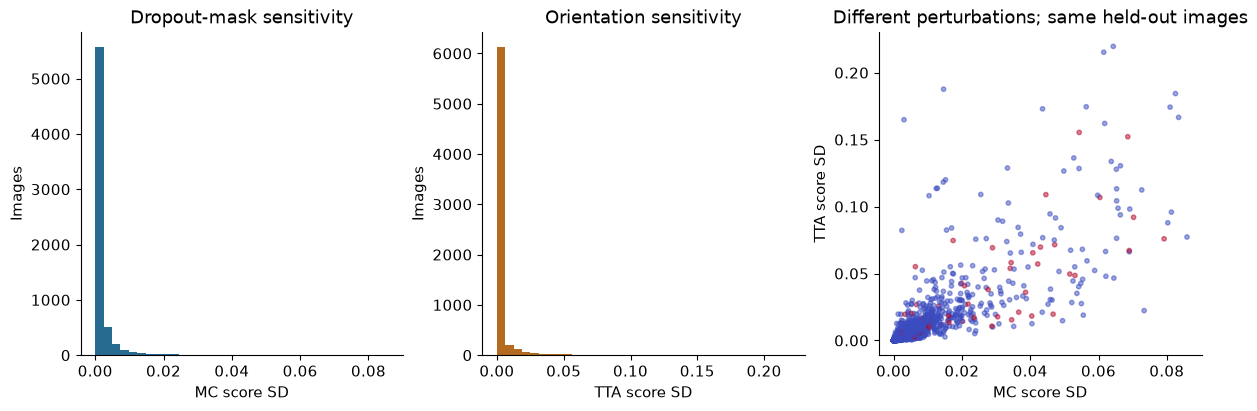

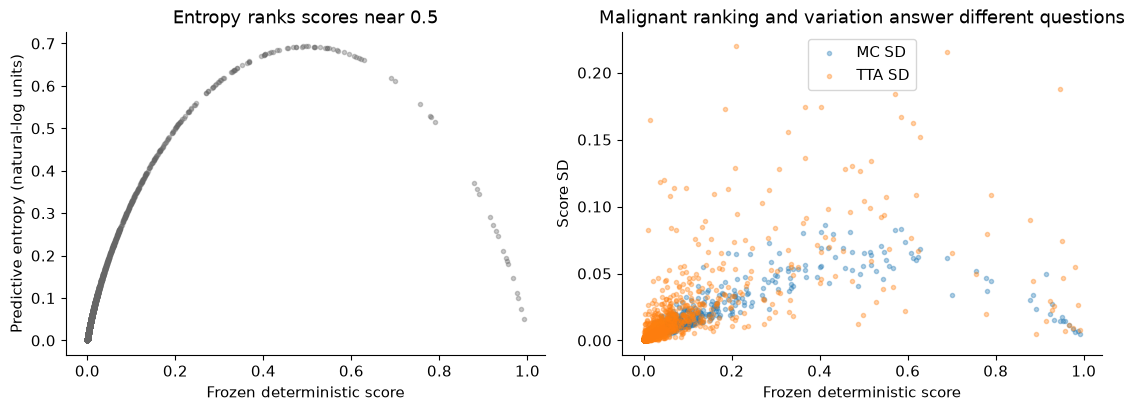

In [8]:
image_docs.uncertainty_distributions(uncertainty, finish_figure)

## Referral order with fixed underlying decisions

Set aside the prescribed fractions 0%, 5%, 10%, 20%, 30%, 40% and 50% for review. Compare descending SD, ordinary score, predictive entropy and the mean of 100 seeded random rankings (seed 17042). All methods retain the same deterministic classification score and descriptive cutoff 0.5, so differences isolate ordering. Patient and malignant-patient counts show support; referred images are not assumed correctly diagnosed.

,method,ranking,n_images,n_patients,n_malignant_images,n_malignant_patients,n_referred,n_malignant_images_referred,n_malignant_patients_referred,retained_error,malignant_referred_fraction
3,mc,uncertainty_sd,6706,422,127,88,1341,77,52,0.009320,0.606299
10,mc,prediction_score,6706,422,127,88,1341,78,53,0.009133,0.614173
17,mc,predictive_entropy,6706,422,127,88,1341,78,53,0.009133,0.614173
724,tta,uncertainty_sd,6706,422,127,88,1341,79,55,0.008947,0.622047
731,tta,prediction_score,6706,422,127,88,1341,78,53,0.009133,0.614173
738,tta,predictive_entropy,6706,422,127,88,1341,78,53,0.009133,0.614173


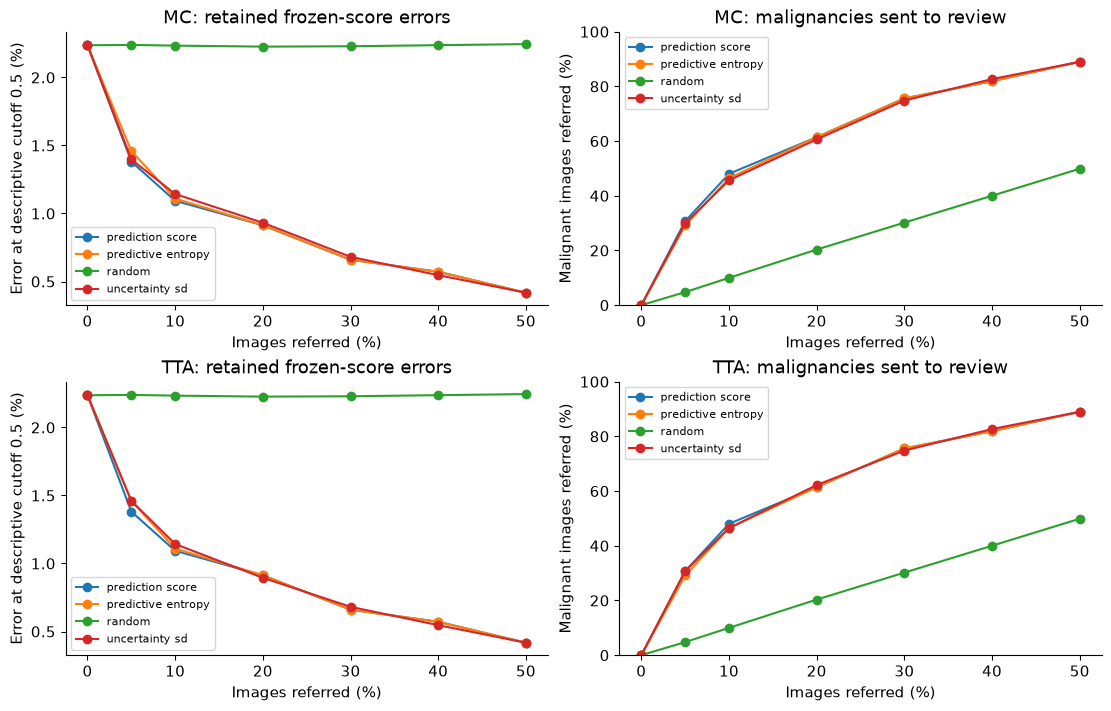

,fold,method,ranking,n_images,n_patients,n_malignant_images,n_malignant_patients,n_referred,n_malignant_images_referred,n_malignant_patients_referred,retained_error,malignant_referred_fraction
3,0,mc,uncertainty_sd,1344,84,24,17,268,15,9,0.008364,0.625000
724,0,tta,uncertainty_sd,1344,84,24,17,268,14,9,0.009294,0.583333
1445,1,mc,uncertainty_sd,1366,84,26,15,273,16,8,0.009149,0.615385
2166,1,tta,uncertainty_sd,1366,84,26,15,273,17,10,0.008234,0.653846
2887,2,mc,uncertainty_sd,1328,87,26,21,265,21,17,0.004704,0.807692
3608,2,tta,uncertainty_sd,1328,87,26,21,265,19,15,0.006585,0.730769
4329,3,mc,uncertainty_sd,1371,82,25,18,274,13,11,0.010939,0.520000
5050,3,tta,uncertainty_sd,1371,82,25,18,274,10,7,0.013674,0.400000
5771,4,mc,uncertainty_sd,1297,85,26,17,259,16,12,0.009634,0.615385
6492,4,tta,uncertainty_sd,1297,85,26,17,259,18,13,0.007707,0.692308


In [9]:
image_docs.uncertainty_referral(uncertainty, finish_figure)

## Paired whole-patient uncertainty intervals

Use 2,000 draws, seed 20242, resampling the original patient count independently within each outer fold. Every ranking and MC/TTA method receives identical patient multiplicities and paired random orders. Recompute rankings and referral counts on every draw. At the predeclared 20% referral, negative retained-error differences favour SD; positive malignant-referral differences favour SD. Undefined malignant fractions remain missing, with valid-draw counts shown.

,method,ranking,comparator,score_column,referral_fraction,metric,estimate,ci_lower,ci_upper,n_requested,n_valid,n_undefined,n_random_per_replicate,bootstrap_seed,referral_seed,resampling
6,mc,uncertainty_sd,prediction_score,base_score,0.2,retained_error,0.000186,-0.000557,0.001310,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
7,mc,uncertainty_sd,prediction_score,base_score,0.2,malignant_referred_fraction,-0.007874,-0.052241,0.024194,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
20,mc,uncertainty_sd,predictive_entropy,base_score,0.2,retained_error,0.000186,-0.000568,0.001162,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
21,mc,uncertainty_sd,predictive_entropy,base_score,0.2,malignant_referred_fraction,-0.007874,-0.052632,0.024194,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
34,mc,uncertainty_sd,random,base_score,0.2,retained_error,-0.012947,-0.017360,-0.009090,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
35,mc,uncertainty_sd,random,base_score,0.2,malignant_referred_fraction,0.402992,0.297141,0.505934,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
48,tta,uncertainty_sd,prediction_score,base_score,0.2,retained_error,-0.000186,-0.001138,0.001399,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
49,tta,uncertainty_sd,prediction_score,base_score,0.2,malignant_referred_fraction,0.007874,-0.059709,0.049597,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
62,tta,uncertainty_sd,predictive_entropy,base_score,0.2,retained_error,-0.000186,-0.001142,0.001288,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
63,tta,uncertainty_sd,predictive_entropy,base_score,0.2,malignant_referred_fraction,0.007874,-0.060000,0.049597,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds


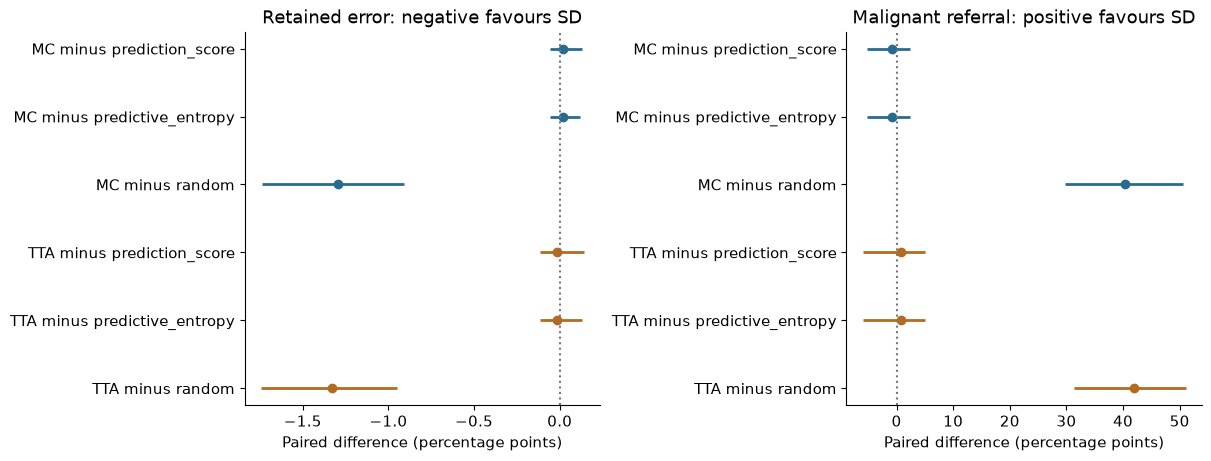

At the predeclared 20% referral, **4 of 4** displayed intervals against score ranking include zero. Read the direction and support counts; these conditional intervals do not establish a clinical policy or a final architecture.

In [10]:
image_docs.uncertainty_intervals(uncertainty, finish_figure)

## Examples from completed clean rankings

Choose examples deterministically by largest MC SD, largest TTA SD and largest ordinary score, breaking ties by image ID. These are case illustrations from saved clean predictions, not automatic exclusions, proof of correctness or a representative quality sample.

,reason,image_id,patient_id,fold,target,base_score,mc_score_sd,tta_score_sd
3086,Largest MC SD,ISIC_4618918,IP_9955501,0,0,0.412199,0.085908,0.077261
713,Largest TTA SD,ISIC_1155483,IP_8753181,0,0,0.210835,0.064324,0.219620
6538,Largest ordinary score,ISIC_9728805,IP_3010556,0,0,0.991087,0.004589,0.007657


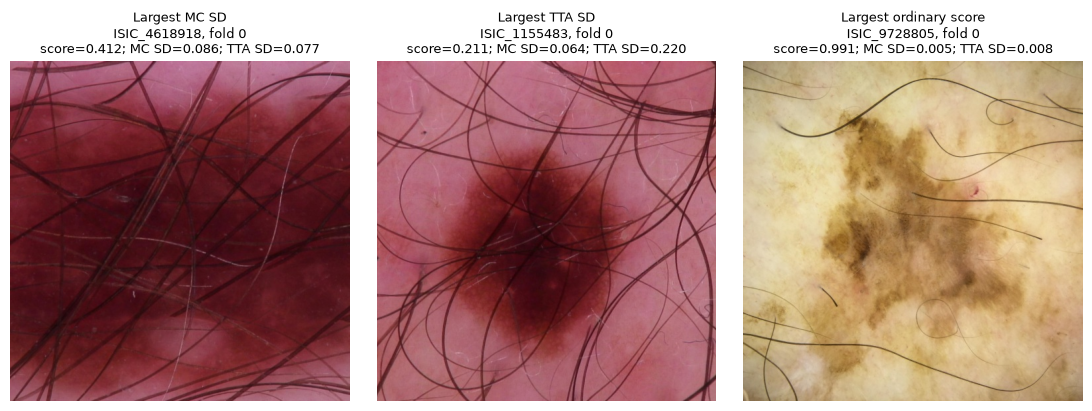

In [11]:
image_docs.uncertainty_examples(uncertainty, ROOT, finish_figure)

## Provenance and limits

Dropout SD covers explicit masks, not backbone stochastic depth, training-seed variation or every source of uncertainty. Four flips cover orientation changes, not new patients or image conditions. Patient-bootstrap intervals condition on fitted checkpoints, selected procedures and the observed inference draws; they omit retraining and selection variability. Keep calibrated decisions and raw diagnostic means separate. No clinical referral policy, final architecture, fusion result or reserved-test performance is established.

In [12]:
if uncertainty["complete"]:
    receipt = uncertainty["receipt"]
    display(pd.DataFrame([{key: receipt[key] for key in ("dataset_manifest_sha256", "bootstrap_sampling", "referral_score", "test_set_loaded", "calibration_fitted", "cutoff_fitted")}]))
else:
    display(Markdown("**Conclusion pending:** completed clean uncertainty exports are required before score variation or referral benefit is interpreted."))

,dataset_manifest_sha256,bootstrap_sampling,referral_score,test_set_loaded,calibration_fitted,cutoff_fitted
0,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...,whole_patients_within_outer_folds,frozen_saved_deterministic_base_score,False,False,False


## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.